# Chapter 6 — Building Your First Deep Neural Network: Introduction to Backpropagation

> **Book:** *Grokking Deep Learning* (Andrew W. Trask, Manning)
> **Notebook goal:** summarize Chapter 6, explain every theory, and reproduce the code (streetlight problem, 2-layer network, backpropagation).

---

## 1. Chapter Summary

The chapter solves the **streetlight problem**: a pedestrian must decide to *walk* or *stop* by looking at three traffic-light bulbs. Two datasets are used: **dataset A** (6 examples, the middle light alone tells us the answer) and **dataset B** (4 examples, the answer is a *pattern* of lights, "left XOR middle").

Main steps:

1. **Prepare the data** — a matrix of lights (input) and a vector of walk/stop (target).
2. **Matrices and the matrix relationship** — a dataset is a matrix; each row = one example; the network turns a matrix into a matrix.
3. **Build a (one-layer) network** and train it with the gradient descent from Ch.5. On dataset A it works: it discovers that the *middle light* is perfectly correlated with "walk". On dataset B it **fails** — a single layer can only find **direct correlation** between an input and the output.
4. **The key insight — correlation**: A network searches for correlation between the input and the output. In dataset B *no individual light* is correlated with the target; only a **pattern/combination** is. A single layer cannot create intermediate patterns.
5. **Creating correlation** — add a **hidden layer**, which creates *intermediate datasets* with correlation to the output; each hidden node is a **sub-detector** (e.g. "is the middle light off?").
6. **Non-linearity** — stacking two linear layers collapses to a single linear layer, so we need a **non-linear activation** (ReLU) so that hidden nodes can *selectively* correlate with different patterns ("sometimes correlation": turn off when negative).
7. **Backpropagation** — to learn the first-layer weights we need to know how much *each hidden node* contributed to the final error. We propagate the error **backwards**: `layer_1_delta = layer_2_delta · W₂ᵀ × relu'(layer_1)`.
8. Putting it all together: a complete 3-layer network (input → hidden(ReLU) → output) trained end to end that reaches ≈ 0 error.

---

## 2. Theory Deep-Dive

### 2.1 Data as matrices
Dataset A (solvable by one layer) and dataset B (needs a hidden layer):

$$X_A=\begin{bmatrix}1&0&1\\0&1&1\\0&0&1\\1&1&1\\0&1&1\\1&0&1\end{bmatrix},\ \mathbf y_A=\begin{bmatrix}0\\1\\0\\1\\1\\0\end{bmatrix}\qquad\qquad X_B=\begin{bmatrix}1&0&1\\0&1&1\\0&0&1\\1&1&1\end{bmatrix},\ \mathbf y_B=\begin{bmatrix}1\\1\\0\\0\end{bmatrix}$$

Rows = examples, columns = features. Predicting for the whole matrix at once is `X · w`.

### 2.2 Why a single layer fails: "correlation"
A weight goes up when its input is *positively* correlated with the target and down when it is *negatively* correlated.

* **Dataset A:** the middle light is *perfectly* correlated with the target (+1.0), so a single weight of ≈1 on it solves the task.
* **Dataset B:** "walk" happens when exactly one of left/middle is on. Left ↔ walk is 0 correlated, middle ↔ walk is 0 correlated, and the last column is a constant `1`. *No single bulb tells the answer*, only a combination (XOR). One weight per bulb can't express that: the best a single layer can do is output ≈ 0.5 everywhere (error 1.0).

> Statement from the book: **"Neural networks *search for correlation* between input and output layers."**

### 2.3 Hidden layers create correlation
$$\mathbf h = \text{relu}(X W_1),\qquad \hat y = \mathbf h W_2$$
Each hidden unit computes its own weighted sum of the lights, thereby *inventing a new feature* that can be correlated with the answer even when the raw inputs are not.

### 2.4 Why non-linearity? (and ReLU)
Without an activation, $\hat y = (XW_1)W_2 = X(W_1W_2)$ — one layer in disguise. **ReLU** $\text{relu}(x)=\max(0,x)$ makes a node *"correlate sometimes"*: negative signals are silenced, so the node only participates when it is *strongly positive*; this lets different hidden nodes specialise on different patterns. Its derivative is `1` if $x>0$, else `0`.

### 2.5 Backpropagation
Forward pass: `layer_0 → layer_1 → layer_2`. For the loss $E=\sum(\hat y-y)^2$:

1. Output error: $\delta_2=\hat y-y$
2. Gradient of $W_2$: $\Delta W_2 = \mathbf h^T\delta_2$
3. **Back-propagate** to hidden: $\delta_1=(\delta_2 W_2^T)\odot \text{relu}'(\mathbf h)$   — "how much did each hidden node contribute to the error, if it was active?"
4. Gradient of $W_1$: $\Delta W_1 = X^T\delta_1$
5. Update: $W\leftarrow W-\alpha\,\Delta W$

This is simply the **chain rule** of calculus, organised layer by layer ("cross-communication"). The mantra: *"gradient descent with an extra step that tells the hidden layer what to learn."*

---

## 3. Code Reproduction

### 3.1 The streetlight datasets

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("folder-picture", exist_ok=True)

# Dataset A: the middle light decides
streetlights_A = np.array([[1, 0, 1],
                           [0, 1, 1],
                           [0, 0, 1],
                           [1, 1, 1],
                           [0, 1, 1],
                           [1, 0, 1]])
walk_A = np.array([[0], [1], [0], [1], [1], [0]])

# Dataset B: walk iff exactly one of (left, middle) is on  -> a *pattern*, not a single light
streetlights_B = np.array([[1, 0, 1],
                           [0, 1, 1],
                           [0, 0, 1],
                           [1, 1, 1]])
walk_B = np.array([[1], [1], [0], [0]])

def show_corr(X, y, title):
    print(title)
    for i, name in enumerate(["left", "middle", "right"]):
        col = X[:, i]
        c = np.corrcoef(col, y[:, 0])[0, 1] if col.std() > 0 else 0.0   # constant column -> 0
        print(f"  correlation({name:6s}, walk) = {c:+.2f}")

show_corr(streetlights_A, walk_A, "Dataset A:")
show_corr(streetlights_B, walk_B, "Dataset B:")

Dataset A:
  correlation(left  , walk) = -0.33
  correlation(middle, walk) = +1.00
  correlation(right , walk) = +0.00
Dataset B:
  correlation(left  , walk) = +0.00
  correlation(middle, walk) = +0.00
  correlation(right , walk) = +0.00


### 3.2 One-layer network trained by gradient descent (per-example)

We train the same one-layer network on both datasets.

In [2]:
def train_one_layer(X, y, alpha=0.1, iters=60, seed=1):
    np.random.seed(seed)
    weights = 2 * np.random.random((3, 1)) - 1
    errors = []
    for iteration in range(iters):
        total = 0
        for i in range(len(X)):
            layer_0 = X[i:i+1]
            layer_1 = layer_0.dot(weights)
            delta   = layer_1 - y[i:i+1]
            total  += float((delta ** 2).sum())
            weights = weights - alpha * layer_0.T.dot(delta)
        errors.append(total)
    return weights, errors

wA, errA = train_one_layer(streetlights_A, walk_A)
wB, errB = train_one_layer(streetlights_B, walk_B)

print("Dataset A -> final error:", round(errA[-1], 6), " weights:", wA.ravel().round(3))
print("   predictions:", streetlights_A.dot(wA).ravel().round(2), " targets:", walk_A.ravel())
print("Dataset B -> final error:", round(errB[-1], 4), " weights:", wB.ravel().round(3))
print("   predictions:", streetlights_B.dot(wB).ravel().round(2), " targets:", walk_B.ravel())

Dataset A -> final error: 8e-06  weights: [ 0.002  1.002 -0.002]
   predictions: [-0.  1. -0.  1.  1. -0.]  targets: [0 1 0 1 1 0]
Dataset B -> final error: 1.2378  weights: [ 0.009 -0.046  0.432]
   predictions: [0.44 0.39 0.43 0.4 ]  targets: [1 1 0 0]


* **Dataset A:** error → 0 and the weight on the *middle* light ≈ 1 (the others ≈ 0): the network found the direct correlation.
* **Dataset B:** the error gets stuck above **1.0** (1.0 is the best any linear model can reach: predicting 0.5 for every example; per-example SGD hovers slightly above it), and the predictions are all ≈ 0.4–0.5: *a single layer cannot create correlation*.

### 3.3 The 3-layer network with ReLU and backpropagation (dataset B)

In [3]:
np.random.seed(1)

def relu(x):
    return (x > 0) * x                 # returns x if x > 0, else 0

def relu2deriv(output):
    return output > 0                  # 1 when output > 0, else 0

alpha = 0.2
hidden_size = 4

weights_0_1 = 2 * np.random.random((3, hidden_size)) - 1
weights_1_2 = 2 * np.random.random((hidden_size, 1)) - 1

deep_errors = []
for iteration in range(60):
    layer_2_error = 0
    for i in range(len(streetlights_B)):
        layer_0 = streetlights_B[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))          # forward
        layer_2 = np.dot(layer_1, weights_1_2)

        layer_2_error += np.sum((layer_2 - walk_B[i:i+1]) ** 2)

        layer_2_delta = layer_2 - walk_B[i:i+1]                                 # output error
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)  # BACKPROP

        weights_1_2 -= alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 -= alpha * layer_0.T.dot(layer_1_delta)
    deep_errors.append(layer_2_error)
    if iteration % 10 == 9:
        print(f"Error: {layer_2_error:.6f}")

Error: 0.634231
Error: 0.358384
Error: 0.083018
Error: 0.006467
Error: 0.000329
Error: 0.000015


The error drops to ≈ 0 — the hidden layer solves the problem that the single layer could not.

### 3.4 Visualising what happened

predictions: [1.    0.999 0.003 0.   ]
targets    : [1 1 0 0]


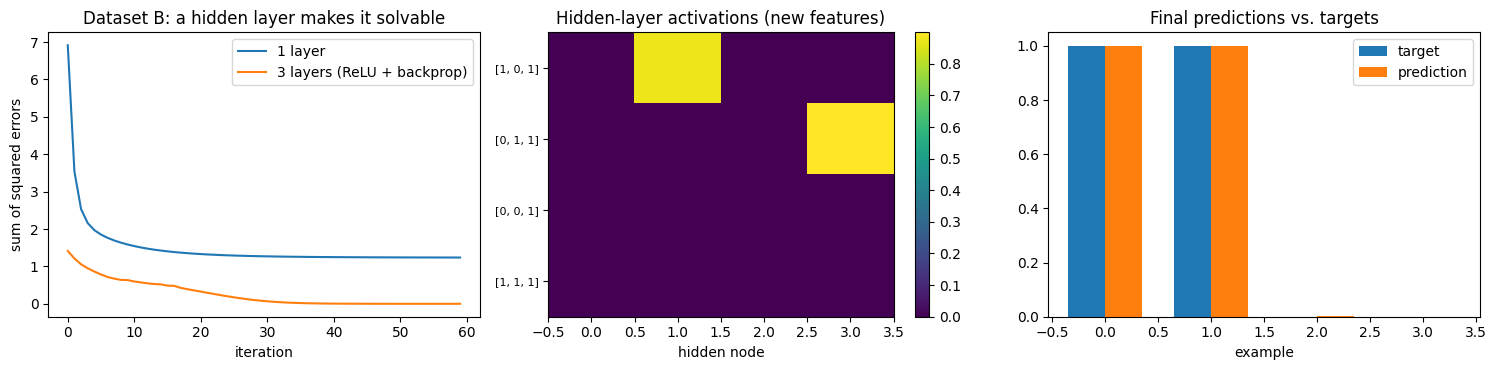

In [4]:
final_h = relu(streetlights_B.dot(weights_0_1))
final_pred = final_h.dot(weights_1_2)
print("predictions:", final_pred.ravel().round(3))
print("targets    :", walk_B.ravel())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(errB, label="1 layer"); ax[0].plot(deep_errors, label="3 layers (ReLU + backprop)")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("sum of squared errors"); ax[0].legend()
ax[0].set_title("Dataset B: a hidden layer makes it solvable")

im = ax[1].imshow(final_h, cmap="viridis", aspect="auto")
ax[1].set_yticks(range(4)); ax[1].set_yticklabels([str(r) for r in streetlights_B.tolist()], fontsize=8)
ax[1].set_xlabel("hidden node"); ax[1].set_title("Hidden-layer activations (new features)")
plt.colorbar(im, ax=ax[1])

width = 0.35
ax[2].bar(np.arange(4) - width / 2, walk_B.ravel(), width, label="target")
ax[2].bar(np.arange(4) + width / 2, final_pred.ravel(), width, label="prediction")
ax[2].set_xlabel("example"); ax[2].set_title("Final predictions vs. targets"); ax[2].legend()
plt.tight_layout()
plt.savefig("folder-picture/ch06_deep_network_streetlight.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.5 Why the ReLU matters — linear hidden layer collapses

Replacing ReLU by the identity makes the 3-layer network equivalent to a single layer, so on dataset B it stalls at the same error as the one-layer network.

final error, linear 3-layer net: 1.3602 (stuck above 1.0, just like the one-layer net)
final error, ReLU 3-layer net  : 1.5e-05


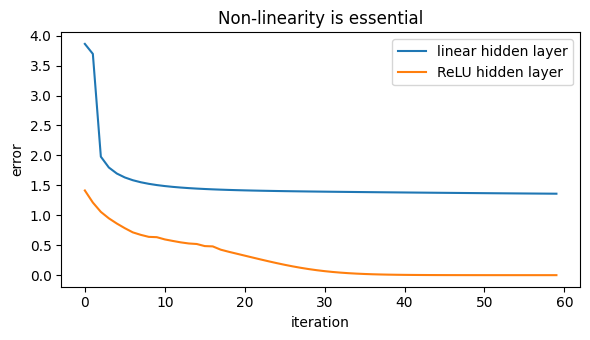

In [5]:
np.random.seed(1)
w01 = 2 * np.random.random((3, hidden_size)) - 1
w12 = 2 * np.random.random((hidden_size, 1)) - 1
lin_errors = []
for iteration in range(60):
    tot = 0
    for i in range(len(streetlights_B)):
        l0 = streetlights_B[i:i+1]
        l1 = l0.dot(w01)                       # NO non-linearity
        l2 = l1.dot(w12)
        d2 = l2 - walk_B[i:i+1]
        d1 = d2.dot(w12.T)
        tot += float((d2 ** 2).sum())
        w12 -= alpha * l1.T.dot(d2)
        w01 -= alpha * l0.T.dot(d1)
    lin_errors.append(tot)
print("final error, linear 3-layer net:", round(lin_errors[-1], 4), "(stuck above 1.0, just like the one-layer net)")
print("final error, ReLU 3-layer net  :", round(deep_errors[-1], 6))

plt.figure(figsize=(6, 3.5))
plt.plot(lin_errors, label="linear hidden layer"); plt.plot(deep_errors, label="ReLU hidden layer")
plt.xlabel("iteration"); plt.ylabel("error"); plt.legend(); plt.title("Non-linearity is essential")
plt.tight_layout()
plt.savefig("folder-picture/ch06_relu_vs_linear.png", dpi=120, bbox_inches="tight")
plt.show()

---

## 4. Key Takeaways

* A network learns by **finding correlation** between its input and output (dataset A: the middle light).
* When no direct correlation exists, a **hidden layer** can create *intermediate* correlated features.
* Stacked linear layers collapse into one — a **non-linearity** (ReLU) is required for depth to help.
* **Backpropagation** = chain rule: `layer_1_delta = layer_2_delta · W₂ᵀ × relu'(layer_1)` tells each hidden node how to change.
* The recipe: *forward pass → compute deltas backwards → update every weight matrix with `alpha × layerᵀ · delta`.*

✅ This completes **Chapters 1-6** (first submission deadline). Chapters 7-10 follow.